In [ ]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from src.data import REPO_ROOT
from src.splits import make_splits
from src.metrics import bootstrap_auc

DATA = REPO_ROOT / "data"
cache_path = DATA / "processed" / "images_224.npy"
meta = pd.read_csv(DATA / "metadata.csv")
train, val, test = make_splits(meta)
splits = pd.concat([train, val, test])
splits.to_csv(DATA / "splits.csv", index=False)
print(splits.groupby("split").agg(n=("target", "size"), prevalence=("target", "mean"),
                                  ap_share=("view", lambda v: (v == "AP").mean())))

def meta_features(d):
    return pd.DataFrame({"is_ap": (d.view == "AP").astype(int),
                         "is_male": (d.sex == "M").astype(int),
                         "age": d.age / 100})

b1 = LogisticRegression().fit(meta_features(train), train.target)
test = test.assign(p_b1=b1.predict_proba(meta_features(test))[:, 1])

print("B1 overall: AUC = %.3f [%.3f, %.3f]" % bootstrap_auc(test.target, test.p_b1))
for v in ["AP", "PA"]:
    t = test[test.view == v]
    print(f"B1 within {v}: AUC = %.3f [%.3f, %.3f]" % bootstrap_auc(t.target, t.p_b1))

           n  prevalence  ap_share
split                             
test    4002    0.225387  0.456272
train  18675    0.225328  0.456278
val     4002    0.225387  0.456272
B1 overall: AUC = 0.727 [0.709, 0.746]
B1 within AP: AUC = 0.552 [0.524, 0.578]
B1 within PA: AUC = 0.545 [0.504, 0.588]


In [2]:
from src.data import find_data_root
from src.preprocess import build_image_cache

build_image_cache(find_data_root(), splits.patientId, DATA / "processed" / "images_224.npy")

Caching images: 100%|██████████| 26679/26679 [12:41<00:00, 35.04it/s]


Test

(26679, 224, 224) uint8 0 255


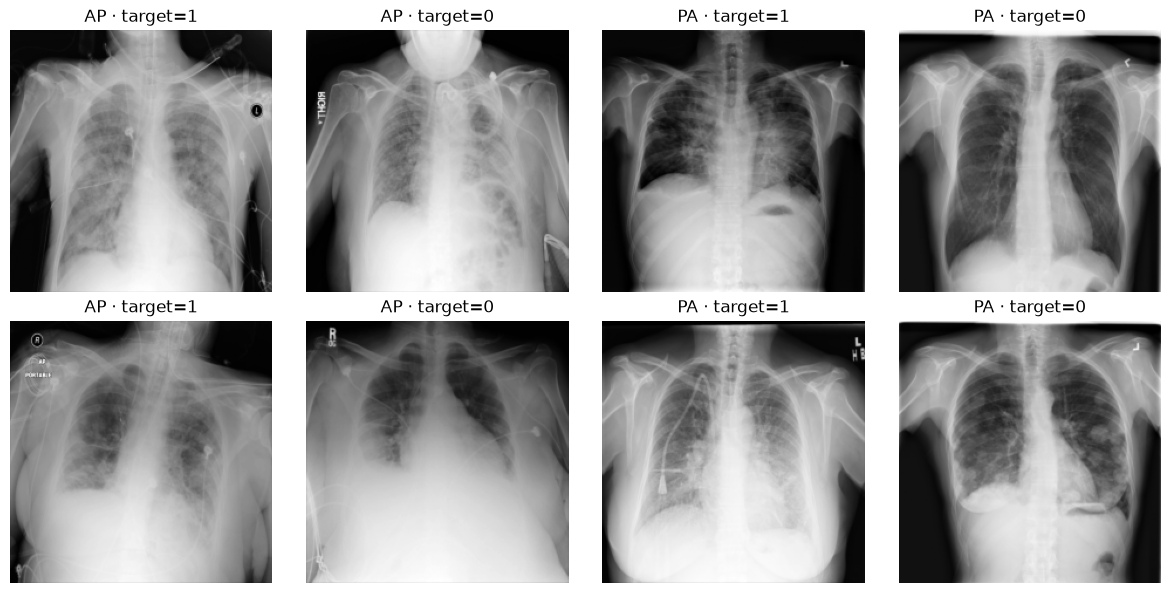

In [3]:
import numpy as np, matplotlib.pyplot as plt

images = np.load(DATA / "processed" / "images_224.npy", mmap_mode="r")
index = pd.read_csv(DATA / "processed" / "images_224.index.csv")
print(images.shape, images.dtype, images.min(), images.max())
assert (index.patientId.values == splits.patientId.values).all()

row = splits.reset_index(drop=True)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, (view, target) in zip(axes.flat, [("AP", 1), ("AP", 0), ("PA", 1), ("PA", 0)] * 2):
    i = row[(row.view == view) & (row.target == target)].sample(1).index[0]
    ax.imshow(images[i], cmap="gray"); ax.set_title(f"{view} · target={target}"); ax.axis("off")
plt.tight_layout()

In [ ]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from src.data import REPO_ROOT

DATA = REPO_ROOT / "data"
splits = pd.read_csv(DATA / "splits.csv")
train, test = splits[splits.split == "train"], splits[splits.split == "test"].copy()

def meta_features(d):
    return pd.DataFrame({"is_ap": (d.view == "AP").astype(int),
                         "is_male": (d.sex == "M").astype(int),
                         "age": d.age / 100})

b1 = LogisticRegression().fit(meta_features(train), train.target)
test["p_b1"] = b1.predict_proba(meta_features(test))[:, 1]

In [3]:
from torch.utils.data import DataLoader
from src.dataset import CachedCXRDataset
from src.models import load_xrv_densenet, predict_logits
from src.metrics import auc_by_group
from src.utils import get_device

model = load_xrv_densenet()
print([p for p in model.pathologies if p])          # check that the two outputs exist

loader = DataLoader(CachedCXRDataset(cache_path, test.patientId), batch_size=64, num_workers=0)
logits = predict_logits(model, loader, get_device())

for name in ["Lung Opacity", "Pneumonia"]:
    test[f"e0_{name.lower().replace(' ', '_')}"] = logits[:, model.pathologies.index(name)]

results = pd.concat([auc_by_group(test, c) for c in ["p_b1", "e0_lung_opacity", "e0_pneumonia"]])
print(results.round(3).to_string(index=False))

(DATA / "predictions").mkdir(exist_ok=True)
test.to_csv(DATA / "predictions" / "test_b1_e0.csv", index=False)

If this fails you can run `wget https://github.com/mlmed/torchxrayvision/releases/download/v1/chex-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt -O /Users/xabieralbizuarias/.torchxrayvision/models_data/chex-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt`
[██████████████████████████████████████████████████]
['Atelectasis', 'Consolidation', 'Pneumothorax', 'Edema', 'Effusion', 'Pneumonia', 'Cardiomegaly', 'Lung Lesion', 'Fracture', 'Lung Opacity', 'Enlarged Cardiomediastinum']


Predict: 100%|██████████| 63/63 [01:10<00:00,  1.13s/it]


 subset   auc  ci_low  ci_high           model
overall 0.727   0.709    0.746            p_b1
     AP 0.552   0.524    0.578            p_b1
     PA 0.545   0.504    0.588            p_b1
overall 0.779   0.762    0.794 e0_lung_opacity
     AP 0.695   0.670    0.719 e0_lung_opacity
     PA 0.747   0.713    0.778 e0_lung_opacity
overall 0.749   0.732    0.766    e0_pneumonia
     AP 0.692   0.667    0.715    e0_pneumonia
     PA 0.724   0.687    0.760    e0_pneumonia
